In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

In [3]:
df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")

In [4]:
print(df.shape)       # (rows, columns)

(4340, 8)


In [5]:
print(df.head())      # first 5 rows

                       name  year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007          60000      70000  Petrol   
1  Maruti Wagon R LXI Minor  2007         135000      50000  Petrol   
2      Hyundai Verna 1.6 SX  2012         600000     100000  Diesel   
3    Datsun RediGO T Option  2017         250000      46000  Petrol   
4     Honda Amaze VX i-DTEC  2014         450000     141000  Diesel   

  seller_type transmission         owner  
0  Individual       Manual   First Owner  
1  Individual       Manual   First Owner  
2  Individual       Manual   First Owner  
3  Individual       Manual   First Owner  
4  Individual       Manual  Second Owner  


In [6]:
print(df.dtypes)      # type of each column

name             object
year              int64
selling_price     int64
km_driven         int64
fuel             object
seller_type      object
transmission     object
owner            object
dtype: object


In [7]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()
print(numeric_cols)
print(categorical_cols)

['year', 'selling_price', 'km_driven']
['name', 'fuel', 'seller_type', 'transmission', 'owner']


In [8]:
print(df.isnull().sum())      # missing values
print(df.duplicated().sum())  # duplicate rows
print(df["fuel"].value_counts())
print(df["owner"].value_counts())

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64
763
fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64
owner
First Owner             2832
Second Owner            1106
Third Owner              304
Fourth & Above Owner      81
Test Drive Car            17
Name: count, dtype: int64


In [9]:
rows_before = df.shape[0]

df = df.drop_duplicates()
df["brand"] = df["name"].str.split().str[0]
df["brand"] = df["brand"].replace({"Land": "Land Rover", "OpelCorsa": "Opel"})
df["car_age"] = 2021 - df["year"]
df["price_lakh"] = df["selling_price"] / 100000

rows_after = df.shape[0]
print(rows_before, rows_after)

4340 3577


In [10]:
print(df[["year", "selling_price", "km_driven", "car_age"]].describe())

              year  selling_price      km_driven      car_age
count  3577.000000   3.577000e+03    3577.000000  3577.000000
mean   2012.962538   4.739125e+05   69250.545709     8.037462
std       4.251759   5.093018e+05   47579.940016     4.251759
min    1992.000000   2.000000e+04       1.000000     1.000000
25%    2010.000000   2.000000e+05   36000.000000     5.000000
50%    2013.000000   3.500000e+05   60000.000000     8.000000
75%    2016.000000   6.000000e+05   90000.000000    11.000000
max    2020.000000   8.900000e+06  806599.000000    29.000000


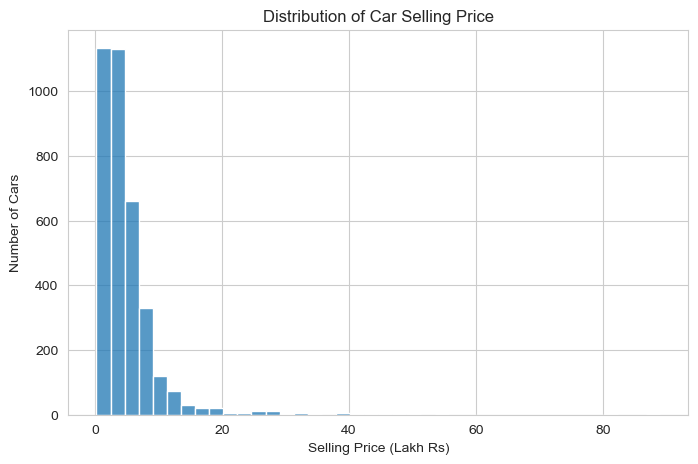

In [11]:
#histogram of price
plt.figure(figsize=(8, 5))
sns.histplot(df["price_lakh"], bins=40)
plt.title("Distribution of Car Selling Price")
plt.xlabel("Selling Price (Lakh Rs)")
plt.ylabel("Number of Cars")
plt.show()

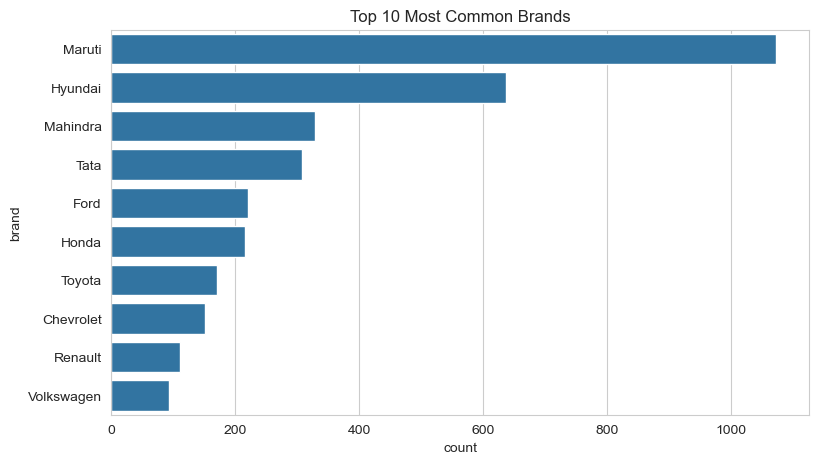

In [12]:
#count plot of top brands
top_brands = df["brand"].value_counts().head(10).index
plt.figure(figsize=(9, 5))
sns.countplot(data=df[df["brand"].isin(top_brands)], y="brand", order=top_brands)
plt.title("Top 10 Most Common Brands")
plt.show()

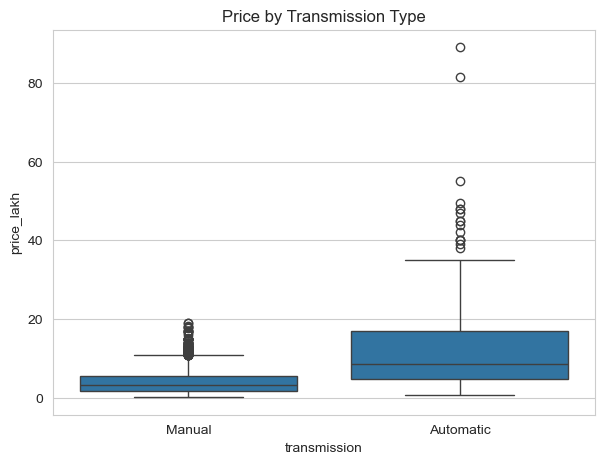

In [13]:
#box plot of price by transmission
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="transmission", y="price_lakh")
plt.title("Price by Transmission Type")
plt.show()

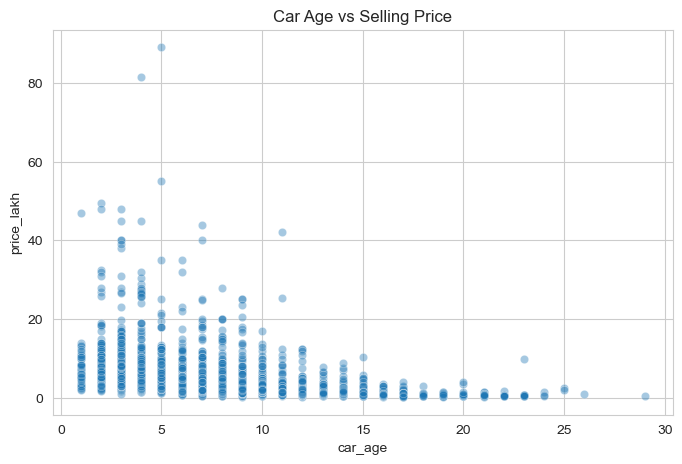

In [14]:
#scatter plot of age vs price
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="car_age", y="price_lakh", alpha=0.4)
plt.title("Car Age vs Selling Price")
plt.show()

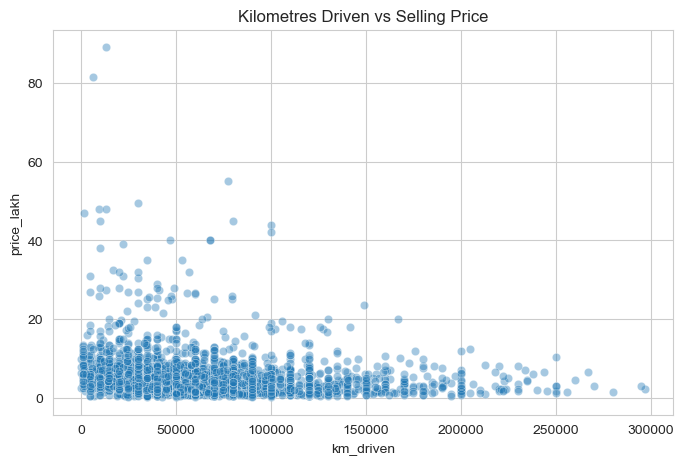

In [15]:
#scatter plot of km driven vs price
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df[df["km_driven"] < 300000], x="km_driven", y="price_lakh", alpha=0.4)
plt.title("Kilometres Driven vs Selling Price")
plt.show()

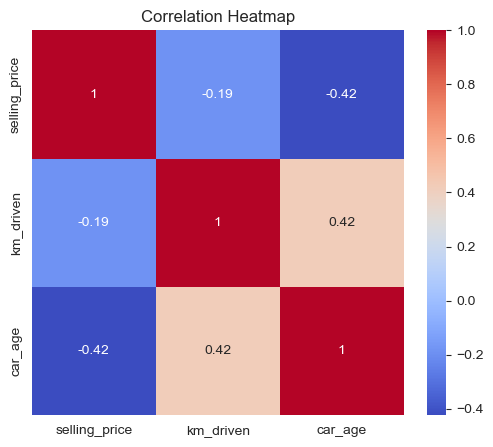

In [16]:
#heatmap of correlations
plt.figure(figsize=(6, 5))
sns.heatmap(df[["selling_price", "km_driven", "car_age"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [17]:
print(df["fuel"].value_counts(normalize=True) * 100)
print(df.groupby("transmission")["price_lakh"].median())
print(df.groupby("owner")["price_lakh"].median())

fuel
Diesel      50.321498
Petrol      48.001118
CNG          1.034386
LPG          0.615041
Electric     0.027956
Name: proportion, dtype: float64
transmission
Automatic    8.55
Manual       3.25
Name: price_lakh, dtype: float64
owner
First Owner             4.50000
Fourth & Above Owner    1.38000
Second Owner            2.67000
Test Drive Car          8.94999
Third Owner             1.90000
Name: price_lakh, dtype: float64
